In [40]:
import pandas as pd
import numpy as np

np.random.seed(42)

# Dataset settings
n_students = 10
samples_per_student = 50
n_features = 10

student_ids = []
face_features = []

# Generate student records in numerical order
for student in range(1, n_students + 1):

    # Unique feature pattern for each student
    student_pattern = np.random.uniform(-2, 2, n_features)

    for sample in range(samples_per_student):

        # Add variation to each face capture
        features = student_pattern + np.random.normal(0, 1.1, n_features)

        face_features.append(features)
        student_ids.append("Student_" + str(student))

# Create feature column names
columns = [
    "Face_Feature_" + str(i)
    for i in range(1, n_features + 1)
]

# Create DataFrame
df = pd.DataFrame(face_features, columns=columns)

# Round features to 2 decimal places
df = df.round(2)

# Add student ID as the first column
df.insert(0, "student_id", student_ids)

# Save dataset without shuffling
df.to_csv("Smart_Attendance_Dataset.csv", index=False)

# Display results
print("Dataset created successfully!")

print("\nFirst 10 records:")
print(df.head(10))

print("\nDataset Shape:", df.shape)

print("\nStudent Distribution:")
print(df["student_id"].value_counts(sort=False))

print("\nMissing Values:", df.isnull().sum().sum())

Dataset created successfully!

First 10 records:
  student_id  Face_Feature_1  Face_Feature_2  Face_Feature_3  Face_Feature_4  \
0  Student_1           -1.02            2.40            0.42           -0.12   
1  Student_1           -1.50            0.25            2.54            0.15   
2  Student_1           -1.16            1.48            0.27            2.43   
3  Student_1           -1.96            2.02            1.74            0.58   
4  Student_1           -0.12           -0.14            1.28           -0.03   
5  Student_1           -0.14            2.88            0.40            0.19   
6  Student_1           -0.10            1.09            1.33            2.09   
7  Student_1           -0.40           -0.38            0.69            0.79   
8  Student_1           -1.08            2.37            1.03            1.46   
9  Student_1           -0.50            1.54           -0.63           -0.07   

   Face_Feature_5  Face_Feature_6  Face_Feature_7  Face_Feature_8  \
0

K-NN Accuracy: 0.76

Classification Report:

              precision    recall  f1-score   support

   Student_1       0.70      0.70      0.70        10
  Student_10       0.69      0.90      0.78        10
   Student_2       0.90      0.90      0.90        10
   Student_3       0.83      1.00      0.91        10
   Student_4       1.00      0.90      0.95        10
   Student_5       0.57      0.80      0.67        10
   Student_6       1.00      0.90      0.95        10
   Student_7       0.50      0.40      0.44        10
   Student_8       0.67      0.60      0.63        10
   Student_9       0.83      0.50      0.62        10

    accuracy                           0.76       100
   macro avg       0.77      0.76      0.76       100
weighted avg       0.77      0.76      0.76       100



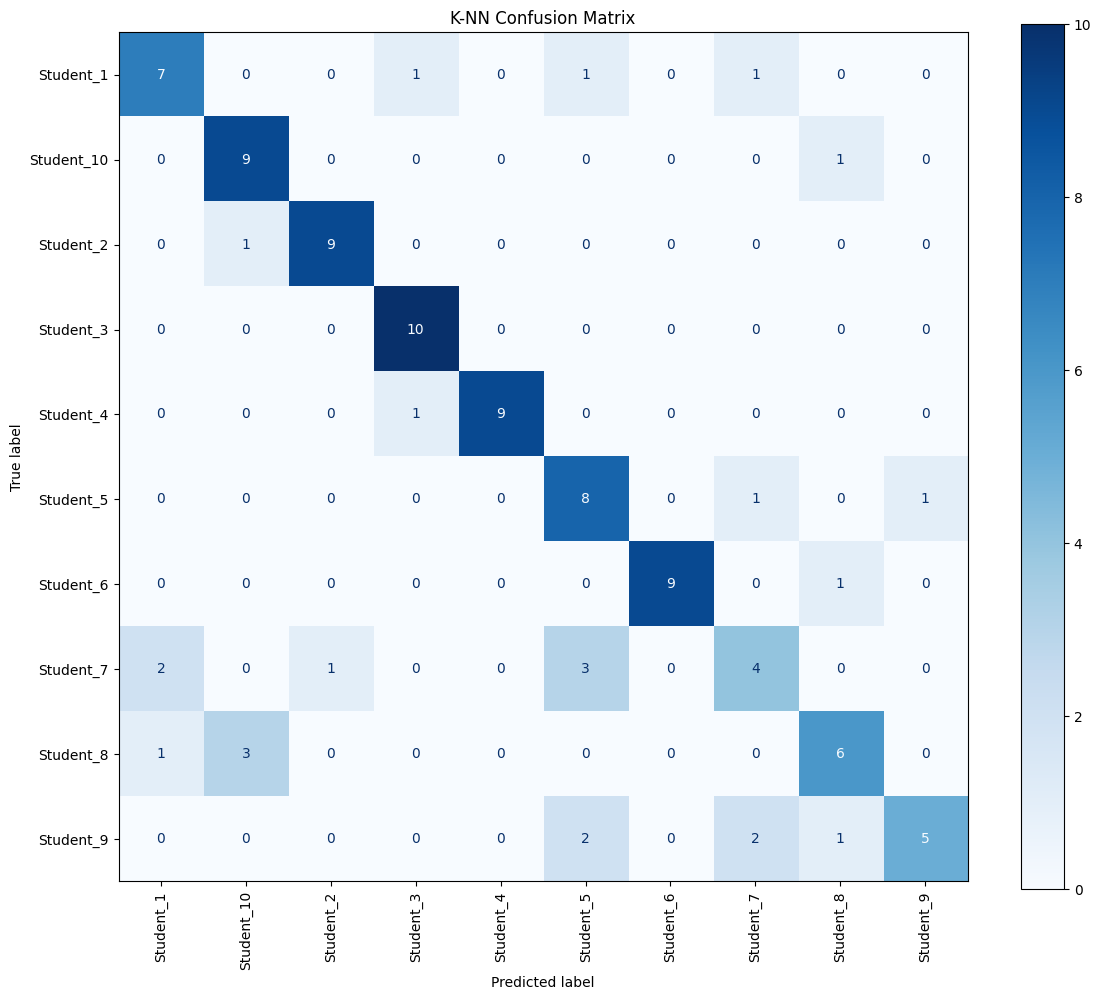

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Separate input and output
X = df.drop("student_id", axis=1)
y = df["student_id"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create k-NN model with scaling
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

# Predict student identities
y_pred = knn_model.predict(X_test)

# Evaluate the model
print("K-NN Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=knn_model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, values_format="d")
plt.title("K-NN Confusion Matrix")
plt.tight_layout()
plt.savefig("KNN_Confusion_Matrix.png", dpi=300, bbox_inches="tight")
plt.show()

ANN Accuracy: 0.75

Classification Report:

              precision    recall  f1-score   support

   Student_1       0.71      0.50      0.59        10
  Student_10       0.86      0.60      0.71        10
   Student_2       0.80      0.80      0.80        10
   Student_3       0.91      1.00      0.95        10
   Student_4       1.00      0.90      0.95        10
   Student_5       0.58      0.70      0.64        10
   Student_6       1.00      0.90      0.95        10
   Student_7       0.50      0.60      0.55        10
   Student_8       0.70      0.70      0.70        10
   Student_9       0.62      0.80      0.70        10

    accuracy                           0.75       100
   macro avg       0.77      0.75      0.75       100
weighted avg       0.77      0.75      0.75       100



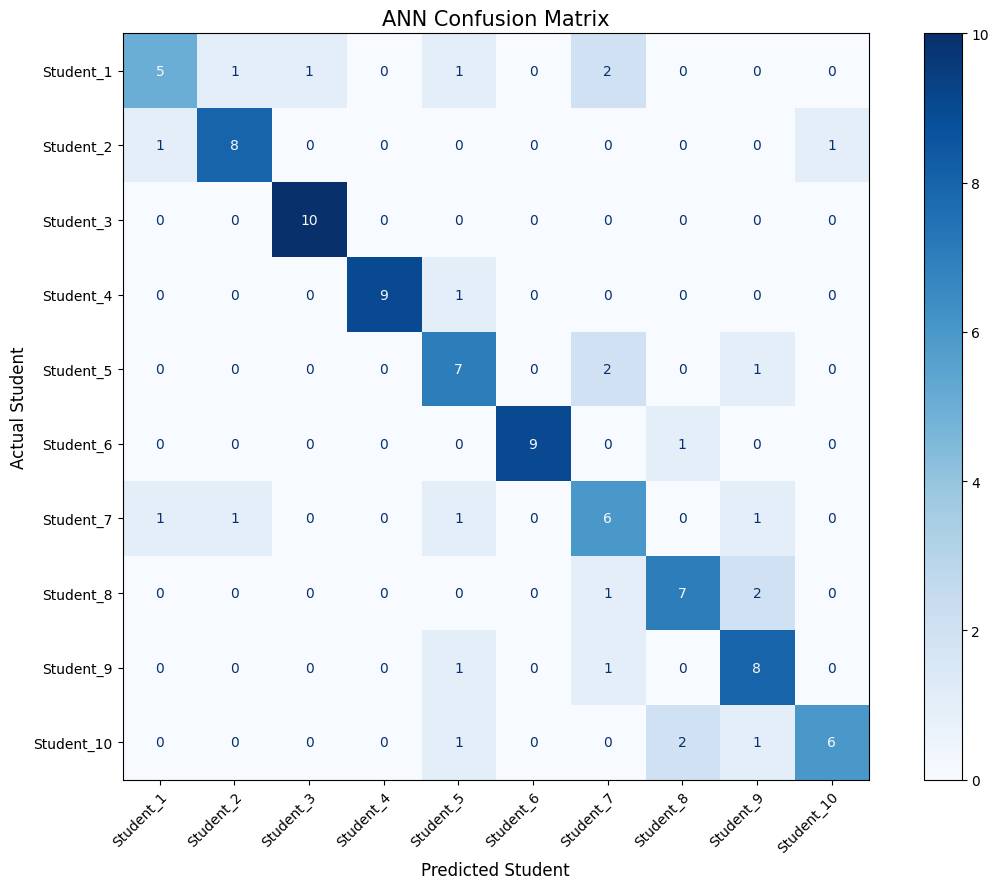

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Separate input and output
X = df.drop("student_id", axis=1)
y = df["student_id"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create ANN model
ann_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        max_iter=1500,
        random_state=42
    ))
])

# Train the model
ann_model.fit(X_train, y_train)

# Predict student identities
y_pred = ann_model.predict(X_test)

# Evaluate model
print("ANN Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Student labels in numerical order
student_order = [f"Student_{i}" for i in range(1, 11)]

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=student_order
)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(12, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=student_order
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

# Fix overlapping student labels
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

plt.setp(
    ax.get_yticklabels(),
    rotation=0
)

plt.title("ANN Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Student", fontsize=12)
plt.ylabel("Actual Student", fontsize=12)

plt.tight_layout()

plt.savefig(
    "ANN_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

K-means Cluster Distribution:
Cluster
0    131
1     63
2     94
3     59
4    153
Name: count, dtype: int64

Silhouette Score: 0.1618

Cluster Feature Means:
         Face_Feature_1  Face_Feature_2  Face_Feature_3  Face_Feature_4  \
Cluster                                                                   
0                 -0.02           -1.62            0.29            1.60   
1                 -1.71           -2.31           -0.92            1.79   
2                  0.40            1.07           -1.46           -1.11   
3                 -1.10            1.44           -1.74            0.26   
4                 -0.52            1.33            1.26            0.69   

         Face_Feature_5  Face_Feature_6  Face_Feature_7  Face_Feature_8  \
Cluster                                                                   
0                  0.23           -0.46           -1.50            1.48   
1                 -1.18           -0.58           -1.66           -0.87   
2              

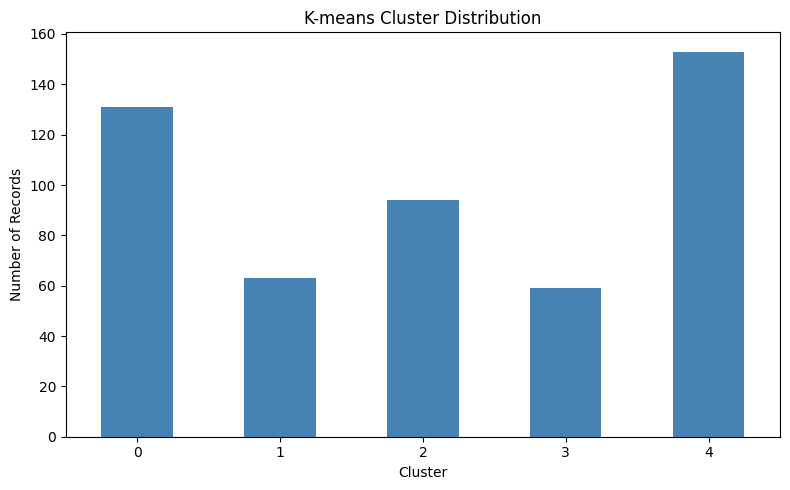

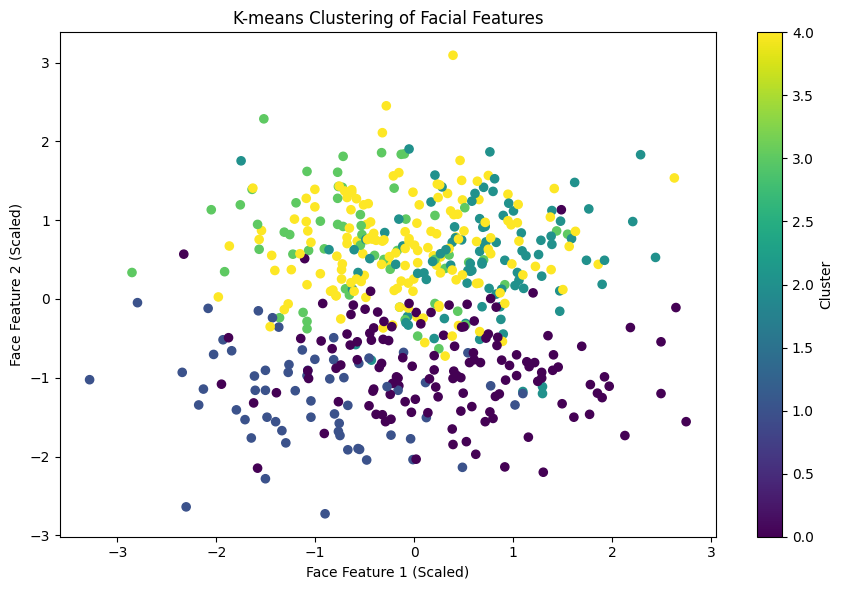

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select facial features only
X = df.drop("student_id", axis=1)

# Standardize facial features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create K-means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train model and assign clusters
clusters = kmeans.fit_predict(X_scaled)

# Create a copy of dataset with cluster labels
clustered_df = df.copy()
clustered_df["Cluster"] = clusters

# Display cluster distribution
print("K-means Cluster Distribution:")
print(clustered_df["Cluster"].value_counts().sort_index())

# Calculate silhouette score
score = silhouette_score(X_scaled, clusters)

print("\nSilhouette Score:", round(score, 4))

# Display average feature values for each cluster
print("\nCluster Feature Means:")
print(
    clustered_df.groupby("Cluster")[X.columns]
    .mean()
    .round(2)
)

# Plot cluster distribution
plt.figure(figsize=(8, 5))

clustered_df["Cluster"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.title("K-means Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("KMeans_Cluster_Distribution.png", dpi=300)
plt.show()

# Visualize clusters using the first two features
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=35
)

plt.title("K-means Clustering of Facial Features")
plt.xlabel("Face Feature 1 (Scaled)")
plt.ylabel("Face Feature 2 (Scaled)")
plt.colorbar(label="Cluster")
plt.tight_layout()

plt.savefig("KMeans_Clustering.png", dpi=300, bbox_inches="tight")
plt.show()

Explained Variance Ratio:
[0.2072 0.1599]

Total Explained Variance:
36.72 %

First 10 PCA Records:
   Principal_Component_1  Principal_Component_2 student_id
0                   0.40                  -0.06  Student_1
1                   1.24                  -0.19  Student_1
2                   0.51                  -0.38  Student_1
3                   0.66                   1.24  Student_1
4                   0.53                  -0.51  Student_1
5                  -0.37                  -0.41  Student_1
6                   1.94                   1.13  Student_1
7                   0.56                   0.20  Student_1
8                   0.07                   0.92  Student_1
9                  -0.59                   0.15  Student_1


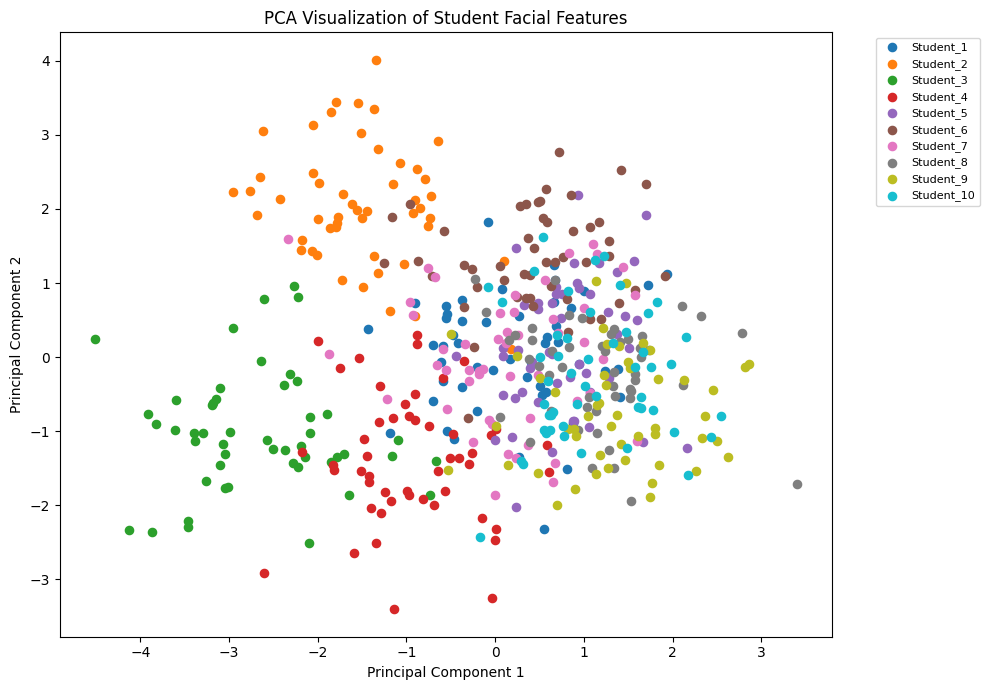

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select facial features
X = df.drop("student_id", axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce 10 features to 2
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal_Component_1", "Principal_Component_2"]
)

pca_df["student_id"] = df["student_id"].values

# Display explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Explained Variance:")
print(round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# Display first 10 PCA records
print("\nFirst 10 PCA Records:")
print(pca_df.head(10).round(2))

# Visualize PCA results
plt.figure(figsize=(10, 7))

for student in sorted(
    pca_df["student_id"].unique(),
    key=lambda x: int(x.split("_")[1])
):
    student_data = pca_df[pca_df["student_id"] == student]

    plt.scatter(
        student_data["Principal_Component_1"],
        student_data["Principal_Component_2"],
        label=student,
        s=35
    )

plt.title("PCA Visualization of Student Facial Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig("PCA_Visualization.png", dpi=300, bbox_inches="tight")
plt.show()